# CNN 연산량 계산

합성곱 한 층은 직접 계산하고, 전체 모델은 제공 도구로 계산합니다.

In [2]:
import math
import numpy as np
import torch
import matplotlib.pyplot as plt
import embedded_lab as lab
from embedded_lab import table

lab.start()

## 1. 실습 모델
입력은 48×48 RGB 이미지이며, 출력은 교통표지 8종의 점수입니다.
이미 학습된 가중치를 불러와 예측합니다. 배치는 한 번에 처리하는 이미지 수입니다.

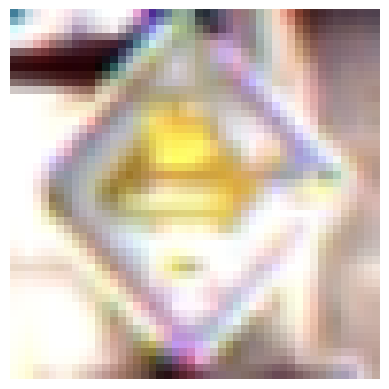

입력: 배치·채널·높이·너비,정답,예측,전체 파라미터 수
"(1, 3, 48, 48)",우선도로,우선도로,89928


In [3]:
model = lab.load()
x = lab.inputs()
names = ['우선도로', '양보', '정지', '진입금지', '도로공사', '우회전', '직진', '우측통행']
with np.load(lab.ROOT / 'sample_images.npz') as data:
    image = data['images'][0]
    truth = int(data['labels'][0])
plt.imshow(image)
plt.axis('off')
plt.show()
with torch.inference_mode():
    predicted = int(model(x).argmax(1).item())
table(['입력: 배치·채널·높이·너비', '정답', '예측', '전체 파라미터 수'],
      [[tuple(x.shape), names[truth], names[predicted], sum(p.numel() for p in model.parameters())]])

## 2. 첫 합성곱 층
입력 채널 3개에 3×3 커널을 적용하므로 출력 값 하나당 **27 MAC**입니다.
출력은 16채널의 48×48이므로 첫 층은 **16×48×48×27 = 995,328 MAC**입니다.

| 구분 | 계산 |
|---|---|
| 가중치 수 | 16×3×3×3 = 432개 |
| MAC 수 | 432×48×48 = 995,328회 |

같은 가중치를 여러 위치에서 사용하므로 파라미터 수와 연산량은 다릅니다.

### ✏️ B01. 합성곱 MAC
이 CNN의 공식은 **출력 값 개수 × 입력 채널 × 커널 높이 × 커널 너비**입니다.
`output_shape`는 `(배치, 출력채널, 높이, 너비)`, `kernel`은 `(커널 높이, 커널 너비)`입니다. `math.prod()`로 묶음 안의 값을 곱해 MAC를 반환하세요.

In [4]:
def conv_mac(output_shape, in_channels, kernel):
    return math.prod(output_shape) * in_channels * math.prod(kernel)
    #raise NotImplementedError('B01 함수를 완성하세요.')

In [5]:
assert conv_mac((1, 16, 48, 48), 3, (3, 3)) == 995328
assert conv_mac((4, 16, 48, 48), 3, (3, 3)) == 4 * 995328
print('B01 완료')

B01 완료


## 3. 모델 전체의 연산량
제공 도구는 **Conv2d·Linear의 MAC**를 세며, **1 MAC = 2 operations**를 적용합니다.
편향 덧셈·정규화·활성화·풀링은 이 집계에서 제외합니다.

In [6]:
rows = lab.count_ops(model, x)
table(['층', '종류', '출력 크기', 'MAC', 'operations'],
      [[r['layer'], r['type'], r['output'], f"{r['mac']:,}", f"{r['ops']:,}"] for r in rows])
assert rows[0]['mac'] == conv_mac((1, 16, 48, 48), 3, (3, 3))
print('첫 층의 직접 계산과 자동 계산이 같습니다.')

층,종류,출력 크기,MAC,operations
net.0,Conv2d,"[1, 16, 48, 48]","995,328","1,990,656"
net.4,Conv2d,"[1, 32, 24, 24]","2,654,208","5,308,416"
net.8,Conv2d,"[1, 64, 12, 12]","2,654,208","5,308,416"
net.13,Linear,"[1, 64]","65,536","131,072"
net.15,Linear,"[1, 8]",512,"1,024"


첫 층의 직접 계산과 자동 계산이 같습니다.


### ✏️ B02. 이미지 한 장의 연산량
층별 MAC 합계를 실제 배치 크기로 나누세요. 한 장당 `mac`, `ops`, `gop`를 dict로 반환합니다.

In [8]:
def summarize(rows, actual_batch):
    mac = sum(row["mac"] for row in rows) / actual_batch
    return dict(mac=mac, ops=2 * mac, gop=2 * mac / 1e9)
    #raise NotImplementedError('B02 함수를 완성하세요.')

In [9]:
assert summarize([{'mac': 100}, {'mac': 300}], 2) == dict(mac=200, ops=400, gop=4e-7)
summary = summarize(rows, x.shape[0])
assert summary['mac'] == 6369792 and summary['ops'] == 12739584
table(['한 장 MAC', '한 장 operations', '한 장 GOP'],
      [[f"{summary['mac']:,.0f}", f"{summary['ops']:,.0f}", summary['gop']]])
print('B02 완료')

한 장 MAC,한 장 operations,한 장 GOP
"6,369,792","12,739,584",0.012739584


B02 완료


## 4. 입력 크기와 배치
입력 크기와 배치를 각각 바꿔 연산량을 비교합니다.
이 모델은 분류기 앞에서 크기를 고정하는 풀링을 사용해 48×48과 96×96 입력을 모두 처리할 수 있습니다.

In [10]:
comparisons = []
for size, batch in [(48, 1), (96, 1), (48, 4)]:
    probe = lab.inputs(size, batch)
    counted = lab.count_ops(model, probe)
    per_image = summarize(counted, probe.shape[0])
    comparisons.append([size, batch, sum(r['mac'] for r in counted), per_image['mac']])
table(['입력 가로·세로', '배치', '배치 전체 MAC', '한 장 MAC'], comparisons)

입력 가로·세로,배치,배치 전체 MAC,한 장 MAC
48,1,6369792,6369792.0
96,1,25281024,25281024.0
48,4,25479168,6369792.0


**확인:** 입력 48→96에서 전체 MAC는 몇 배인가요? 배치 1→4에서는 한 장의 MAC가 변하나요?

**답:**